# DS3 KPIs over time

## Overview
B4 showed that most DS3 KPIs move from run to run by more than their noise, so now we want to know how they move - slow drift, steps at the breaks or jumps in between - and over what timescale ([Phase 01, C1](../../docs/phases/01_eda.md#c1-ds3-kpis-over-time)). Everything builds on B4's kept rows and noise rows, using the shared [analysis package](../../src/qpu_drift/analysis/__init__.py).

**Question.** How do the DS3 KPIs change beyond their noise, and on what timescale?

**Method.** We rebuild B4's series (section 1) and scan the signal ratio over lags for each metric's timescale and block length (section 2). Then we test drift within strata on a chip-wide series (section 3), steps at the breaks against a placebo (section 4) and change points against the register (section 5). Last, we check how much T2 leans on values above the delay sweep (section 6).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.analysis import methods, series
from qpu_drift.analysis.constants import KOLMOGOROV_95, MAIN_METHOD, METRICS, MIN_N, NEAR_EVENT, SIGNAL_MIN
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_kpi_l2, load_runs_l2
from qpu_drift.sources.benchmarking.load import KPI_SUPPLEMENTED_PATH

pd.set_option("display.max_rows", 300, "display.max_columns", 40, "display.width", 250, "display.max_colwidth", 100)
FIG = REPO_ROOT / "docs" / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

LAGS = [1, 2, 3, 4, 7, 14, 28]  # B4 section 4 lags, in DS3 runs
CENSOR_MAX = 0.10  # entities censored above this share are left out of the main analysis
K_MIN = 7  # shortest step window and change-point segment, in runs (the B4 section 5 window)
MIN_UNITS = 5  # elements needed for a chip-wide value
SER = ["metric", "unit", "stratum"]
INCIDENT_STARTS = [i.period[0] for i in periods.INCIDENTS]
EV = series.register_events()
print(f"signal ratio for signal {SIGNAL_MIN}+; pairs per series-lag {MIN_N}+; events within {NEAR_EVENT}; CUSUM critical value {KOLMOGOROV_95};",
      "main noise method per metric:", MAIN_METHOD)

k = series.kpi_rows(load_kpi_l2(path=KPI_SUPPLEMENTED_PATH), load_runs_l2())
kept = series.kept_kpi(k)
nz = series.ds3_noise(load_noise_floor())
print("kept rows per metric:", kept.groupby("metric").size().to_dict())
print("DS3 noise rows (metric, element, regime) per main method:", nz.groupby(["metric", "main_method"]).size().to_dict())

signal ratio for signal 2.0+; pairs per series-lag 20+; events within 2 days 00:00:00; CUSUM critical value 1.358; main noise method per metric: {'T1': ('fit_error_median',), 'T2': ('fit_error_median',), 'fRB': ('seed_error_median', 'fit_error_median_x_sample_seed_ratio'), 'fCX': ('seed_error_median', 'fit_error_median_x_sample_seed_ratio'), 'fRO': ('fit_error_median', 'binomial_upper_median')}


kept rows per metric: {'T1': 16902, 'T2': 13714, 'fCX': 15984, 'fRB': 15578, 'fRO': 20741}
DS3 noise rows (metric, element, regime) per main method: {('T1', 'fit_error_median'): 183, ('T2', 'fit_error_median'): 150, ('fCX', 'fit_error_median_x_sample_seed_ratio'): 74, ('fCX', 'seed_error_median'): 28, ('fRB', 'seed_error_median'): 172, ('fRO', 'binomial_upper_median'): 224}


## 1. Series and checks

We start from B4's kept rows and strata, which `series.kpi_rows` and `series.kept_kpi` rebuild: `ok` rows outside `INCIDENTS`, the f01 flags and retired couplings, split at the `BREAKS` with `SETTLING` on its own and fRB and fCX split again at 2026-06. A series is one metric, element and stratum, with the fCX lengths list counted as part of the element.

Each series takes B4's main noise row. As B4 recommends ([working rules](../../docs/working_rules.md#ds3-kpis)), we leave out entities censored above 10% (they come back in a sensitivity run) and fRO values within 0.02 of the depolarising floor.

The signal ratio uses raw values, as B4 does. Everything else works on $\log_{10} x$ - with $x$ the T1 or T2 in µs, or the infidelity $1 - F$ - so a step reads as a relative change.

In [2]:
cens = series.censored_share(k)
bad = cens[cens > CENSOR_MAX]
print(f"entities censored above {CENSOR_MAX}, per metric:", bad.groupby(level="metric").size().to_dict(),
      "of", cens.groupby(level="metric").size().to_dict())
for mt, g in bad.groupby(level="metric"):
    print(f"  {mt}:", sorted(g.index.get_level_values("element")))
nf = kept["near_floor"] & (kept["metric"] == "fRO")
print("fRO kept values within 0.02 of the floor, left out:", int(nf.sum()),
      "; near-floor kept values of other metrics (kept):", kept[kept["near_floor"] & (kept["metric"] != "fRO")].groupby("metric").size().to_dict())

d = kept[~nf].copy()
d["cens_ok"] = ~pd.MultiIndex.from_frame(d[["metric", "element"]]).isin(bad.index)
d = d.join(nz, on=["metric", "element", "regime"])
d["y"] = d["value_u"]
sers = d.groupby(SER).agg(n=("run", "size"), start=("t", "min"), end=("t", "max"), cens_ok=("cens_ok", "first"),
                          has_noise=("sigma_main", lambda s: s.notna().any()))
print(f"series, rows, and series and rows with a main noise row; series whose entity is censored at most {CENSOR_MAX}:")
display(sers.groupby(level="metric").agg(series=("n", "size"), rows=("n", "sum"), with_noise=("has_noise", "sum"),
                                         rows_with_noise=("n", lambda s: int(s[sers.loc[s.index, "has_noise"]].sum())),
                                         cens_ok=("cens_ok", "sum")))
sn = sers[sers["has_noise"]].reset_index()
print("series with a main noise row per stratum:")
display(sn.pivot_table(index="stratum", columns="metric", values="n", aggfunc="size").reindex(columns=METRICS)
        .sort_index(key=lambda i: i.map(series.stratum_order)).fillna(0).astype(int))
print("first kept time of a series with a main noise row:", sn.groupby("metric")["start"].min().dt.strftime("%Y-%m-%d").to_dict())

entities censored above 0.1, per metric: {'T1': 10, 'T2': 18, 'fCX': 8, 'fRB': 8} of {'T1': 32, 'T2': 32, 'fCX': 34, 'fRB': 32, 'fRO': 32}
  T1: ['1', '16', '18', '19', '23', '24', '28', '32', '34', '6']
  T2: ['1', '11', '15', '16', '20', '21', '23', '24', '25', '26', '27', '28', '30', '31', '33', '34', '6', '9']
  fCX: ['14-15', '18-14', '19-20', '22-18', '24-23', '26-25', '28-21', '28-31']
  fRB: ['11', '15', '22', '25', '26', '28', '32', '33']
fRO kept values within 0.02 of the floor, left out: 53 ; near-floor kept values of other metrics (kept): {}


series, rows, and series and rows with a main noise row; series whose entity is censored at most 0.1:


,series,rows,with_noise,rows_with_noise,cens_ok
metric,,,,,
T1,341,16902,183,15701,242
T2,312,13714,150,12364,154
fCX,487,15984,102,8510,373
fRB,366,15578,172,14093,280
fRO,415,20688,224,19415,415


series with a main noise row per stratum:


metric,T1,T2,fRB,fCX,fRO
stratum,,,,,
1 (2024-05-28),0,0,0,0,32
2 (2024-09-18),32,29,31,0,32
7 (2025-03-28),31,24,29,0,32
8 (2025-07-07),31,19,26,26,32
9 (2025-08-22),31,27,30,31,32
11 (2026-03-24),29,25,27,21,32
13 (2026-05-25),29,26,0,0,32
13 (2026-05-25) RB from 2026-06,0,0,29,24,0


first kept time of a series with a main noise row: {'T1': '2024-10-15', 'T2': '2024-10-15', 'fCX': '2025-07-07', 'fRB': '2024-10-15', 'fRO': '2024-05-28'}


**Results.**

- Kept rows and censoring match B4: censoring is above 10% on 10 of 32 T1 entities, 18 of 32 T2, 8 of 34 fCX, 8 of 32 fRB and no fRO. 53 fRO values near the floor are left out.
- With a main noise row there are T1 183, T2 150, fCX 102, fRB 172 and fRO 224 series. They start on B4's dates - 2024-10-15 for T1, T2 and fRB, 2025-07-07 for fCX and 2024-05-28 for fRO.

## 2. Timescales

Next, how far apart do two runs need to be before a series has moved beyond its noise? As in B4 section 4, $\sigma_L$ is the robust sd of differences $L$ runs apart, over $\sqrt 2$ (`methods.structure_function`), and against the noise sigma $\sigma_n$ the signal ratio is

$$S_L = \left(\frac{\sigma_L}{\sigma_n}\right)^2.$$

Per series, $L^*$ is the first lag where $S_L$ reaches 2, and only series with one go into the per-element tests. Short series drop out at long lags, so the per-metric summaries use the balanced set - series with 20+ pairs at every lag - and $L_\text{var}$ is the first lag where its median $S_L$ reaches 2.

The block length comes from the variance ratio $V_L = (\sigma_L / \sigma_1)^2$: the first lag within 10% of $V_{28}$, or 28 if $V_L$ is still rising past lag 14 (`methods.block_length`). It's the bandwidth for the HAC errors later on, and a block of 28 - no plateau - sends a metric to the jump scan rather than CUSUM in section 5.

In [3]:
sf = methods.structure_function(d, SER, LAGS, col="y", cuts=INCIDENT_STARTS)
sf = sf.join(d.groupby(SER)[["sigma_main", "sigma_lag1"]].first())
sf["ratio"] = (sf["sigma"] / sf["sigma_main"]) ** 2
sf = sf.join(sf.xs(1, level="lag")["sigma"].rename("sigma_1"))
sf["var_ratio"] = (sf["sigma"] / sf["sigma_1"]) ** 2
chk = sf.xs(1, level="lag").dropna(subset=["sigma_lag1"])
print("check: lag-1 sigma here over the B4 lag-1 noise row, median and share within 1e-9, per metric:",
      {mt: (round(float(r.median()), 6), round(float((r - 1).abs().le(1e-9).mean()), 3))
       for mt, r in (chk["sigma"] / chk["sigma_lag1"]).groupby(level="metric")})

ratio_w = sf["ratio"].unstack("lag")
has = ratio_w.notna().any(axis=1)
passed = ratio_w.ge(SIGNAL_MIN)
lstar = pd.Series(np.where(passed.any(axis=1), passed.idxmax(axis=1), np.nan), index=ratio_w.index)
sers = sers.join(lstar.rename("lstar"))
tab = lstar[has].groupby(level="metric").value_counts().unstack().reindex(columns=LAGS).fillna(0).astype(int)
tab["none"] = has.groupby(level="metric").sum() - tab.sum(axis=1)
print("series with a main noise row by L* (smallest lag, in runs, with signal ratio >= 2; none up to 28):")
display(tab)
print(f"the same, series whose entity is censored at most {CENSOR_MAX}:")
ok_c = has & sers["cens_ok"].reindex(has.index)
display(lstar[ok_c].groupby(level="metric").value_counts().unstack().reindex(columns=LAGS).fillna(0).astype(int)
        .assign(none=ok_c.groupby(level="metric").sum() - lstar[ok_c].groupby(level="metric").count()))

# L_var, the block and the timescale fit use the same series at every lag, so the curve is not a change of series
agg = dict(series=("ratio", "size"), ratio_median=("ratio", "median"), share_ge_2=("ratio", lambda s: (s >= SIGNAL_MIN).mean()),
           var_ratio_median=("var_ratio", "median"), days_median=("days", "median"))
full = sf["sigma"].unstack("lag").notna().all(axis=1)
sfb = sf[full.reindex(sf.index.droplevel("lag")).to_numpy()]
pool_b = sfb.dropna(subset=["ratio"]).groupby(["metric", "lag"]).agg(**agg)
print("balanced set (series with 20+ pairs at every lag): series with a main noise row",
      pool_b.xs(1, level="lag")["series"].to_dict(), "of", has.groupby(level="metric").sum().to_dict(),
      "; series for the variance ratio", full.groupby(level="metric").sum().to_dict(), "of", full.groupby(level="metric").size().to_dict())
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pool_b.unstack("metric").swaplevel(axis=1).sort_index(axis=1).reindex(columns=METRICS, level=0))
lvar = {mt: next((L for L, v in g.droplevel("metric").items() if v >= SIGNAL_MIN), np.nan)
        for mt, g in pool_b["ratio_median"].groupby(level="metric")}
vr_all = sfb.groupby(["metric", "lag"])["var_ratio"].median()
block = {mt: methods.block_length(vr_all.xs(mt)) for mt in METRICS}
plateau = {mt: block[mt] < max(LAGS) for mt in METRICS}
print("L_var (smallest lag with median signal ratio >= 2 over the balanced set, runs):", lvar)
print("block length (runs), variance ratio over the balanced set:", block)
print("variance ratio levels off within the lags (change points by CUSUM; else by the jump scan):", plateau)

check: lag-1 sigma here over the B4 lag-1 noise row, median and share within 1e-9, per metric: {'T1': (1.0, 1.0), 'T2': (1.0, 1.0), 'fCX': (1.0, 1.0), 'fRB': (1.0, 1.0), 'fRO': (1.0, 0.987)}
series with a main noise row by L* (smallest lag, in runs, with signal ratio >= 2; none up to 28):


,1,2,3,4,7,14,28,none
metric,,,,,,,,
T1,160,11,5,2,1,1,0,3
T2,49,12,14,9,11,3,4,48
fCX,49,15,9,1,2,1,2,23
fRB,60,16,13,7,6,4,4,62
fRO,155,24,10,9,5,6,4,11


the same, series whose entity is censored at most 0.1:


,1,2,3,4,7,14,28,none
metric,,,,,,,,
T1,118,6,3,2,1,1,0,1
T2,30,8,9,4,8,2,2,20
fCX,41,13,7,1,2,0,1,21
fRB,50,13,10,5,5,4,4,53
fRO,155,24,10,9,5,6,4,11


balanced set (series with 20+ pairs at every lag): series with a main noise row {'T1': 111, 'T2': 91, 'fCX': 29, 'fRB': 89, 'fRO': 159} of {'T1': 183, 'T2': 150, 'fCX': 102, 'fRB': 172, 'fRO': 224} ; series for the variance ratio {'T1': 111, 'T2': 91, 'fCX': 88, 'fRB': 89, 'fRO': 159} of {'T1': 184, 'T2': 151, 'fCX': 164, 'fRB': 173, 'fRO': 224}


metric          T1                                                          T2                                                         fRB                                                         fCX                                                  \
       days_median ratio_median series share_ge_2 var_ratio_median days_median ratio_median series share_ge_2 var_ratio_median days_median ratio_median series share_ge_2 var_ratio_median days_median ratio_median series share_ge_2 var_ratio_median   
lag                                                                                                                                                                                                                                                      
1                1         3.28    111      0.901                1           1         1.35     91      0.319                1           1         1.61     89      0.348                1           1         1.72     29      0.379                1   
2                2         3.75    111      0.937             1.11           2          1.6     91      0.297             1.08           2         1.65     89      0.337             1.04           2         1.85     29      0.414             1.08   
3                3         3.84    111      0.955             1.22           3         1.56     91      0.363              1.2           3         1.64     89      0.326             1.02           3         1.76     29      0.483             1.02   
4                4         3.98    111      0.955             1.19           4          1.5     91      0.352              1.2           4         1.65     89      0.348             1.05           4         1.89     29      0.483             1.14   
7                7         4.35    111      0.937             1.26           7         1.81     91      0.396             1.32           7         1.69     89       0.36             1.11           7         1.89     29      0.448             1.07   
14              14         4.56    111      0.955             1.48        14.1         1.83     91      0.418             1.42          14         1.74     89      0.393             1.06          15         1.93     29      0.448             1.26   
28              30         4.75    111      0.937             1.44          30         2.05     91      0.516             1.53          30         1.85     89      0.449             1.11          30         2.12     29      0.552             1.25   

metric         fRO                                                  
       days_median ratio_median series share_ge_2 var_ratio_median  
lag                                                                 
1                1         2.66    159       0.66                1  
2                2         3.21    159      0.742             1.17  
3                3         3.42    159      0.767             1.31  
4                4         3.66    159      0.786             1.34  
7                7          4.8    159      0.811             1.47  
14              15          5.7    159      0.887             1.78  
28            31.1         5.59    159      0.899                2

L_var (smallest lag with median signal ratio >= 2 over the balanced set, runs): {'T1': 1, 'T2': 28, 'fCX': 28, 'fRB': nan, 'fRO': 1}
block length (runs), variance ratio over the balanced set: {'T1': 14, 'T2': 14, 'fRB': 2, 'fCX': 14, 'fRO': 28}
variance ratio levels off within the lags (change points by CUSUM; else by the jump scan): {'T1': True, 'T2': True, 'fRB': True, 'fCX': True, 'fRO': False}


**Results.**

- The lag-1 sigma matches B4's noise row (median ratio 1.0), so we're on the same footing as B4.
- $L^*$ is lag 1 for most T1 (160 of 183) and fRO (155 of 224) series, but no lag up to 28 gets there for 62 of 172 fRB, 48 of 150 T2 and 23 of 102 fCX series.
- On the balanced set, $L_\text{var}$ is 1 for T1 and fRO and 28 for T2 and fCX. fRB never gets there - its median $S_L$ only goes from 1.61 to 1.85.
- The block is 14 runs for T1, T2 and fCX and 2 for fRB. fRO's is 28, so it gets the jump scan - but only just, since its $V_{28}$ (2.0) is only about 12% above $V_{14}$ (1.78).

To put a number on the timescale, we fit the balanced median curve with

$$S_L = c + a\left(1 - e^{-L/\tau}\right), \qquad c, a \ge 0$$

(`methods.fit_timescale`). $c$ is what's new at every run - it'd be 1 if the noise row were right and nothing else changed from run to run - while $a$ and $\tau$ are the size and length, in runs, of a correlated part. We also fit a random walk $c + bL$ and a constant, and keep the lowest AICc.

timescale fit of the balanced median signal ratio against lag, per metric (c, a in noise units; tau in runs and days); random walk c + b L; best: lowest AICc of exponential, random walk and constant:


,points,c,a,tau,sse,tau_at_edge,rw_c,rw_b,rw_sse,flat_sse,aicc,rw_aicc,flat_aicc,best,days_per_run,tau_days
T1,7,3.01,1.68,4.4,0.0289,False,3.69,0.0449,0.436,1.57,-24.4,-12.4,-7.68,exp,1,4.4
T2,7,1.35,0.706,9.5,0.0391,False,1.49,0.0218,0.0667,0.333,-22.3,-25.6,-18.5,rw,1,9.5
fRB,7,1.61,0.725,71.4,0.000825,False,1.62,0.00835,0.000915,0.0401,-49.3,-55.6,-33.3,rw,1,71.4
fCX,7,1.76,0.717,40.7,0.0146,False,1.77,0.0126,0.0151,0.104,-29.2,-36,-26.7,rw,1,40.7
fRO,7,1.97,3.82,5.65,0.185,False,3.26,0.105,2.53,8.75,-11.4,-0.117,4.36,exp,1,5.65


per-series fits (series with a signal ratio at 5+ lags): medians, share with tau at the grid edge, and share per best model by AICc:


,series,c,a,tau_runs,tau_at_edge,best_exp,best_flat,best_rw
metric,,,,,,,,
T1,177,2.22,4.29,3.81,0.226,0.00565,0.729,0.266
T2,147,0.876,3.05,6.27,0.327,0.0204,0.653,0.327
fRB,168,1.16,1.65,1.75,0.25,0,0.857,0.143
fCX,98,1.26,2.46,2.99,0.224,0.0102,0.724,0.265
fRO,224,1.38,11.7,8.13,0.299,0.067,0.518,0.415


saved docs/figures/eda/c1_structure_function.png
rows for pooled analyses (all entities / censored at most 0.1): {'T1': 15701, 'T2': 12364, 'fCX': 8510, 'fRB': 14093, 'fRO': 19415} {'T1': 11520, 'T2': 7235, 'fCX': 7177, 'fRB': 11864, 'fRO': 19415}
rows for per-element analyses (series with an L*; all entities / censored at most 0.1): {'T1': 15386, 'T2': 8459, 'fCX': 6041, 'fRB': 8607, 'fRO': 18214} {'T1': 11443, 'T2': 5578, 'fCX': 4896, 'fRB': 7114, 'fRO': 18214}


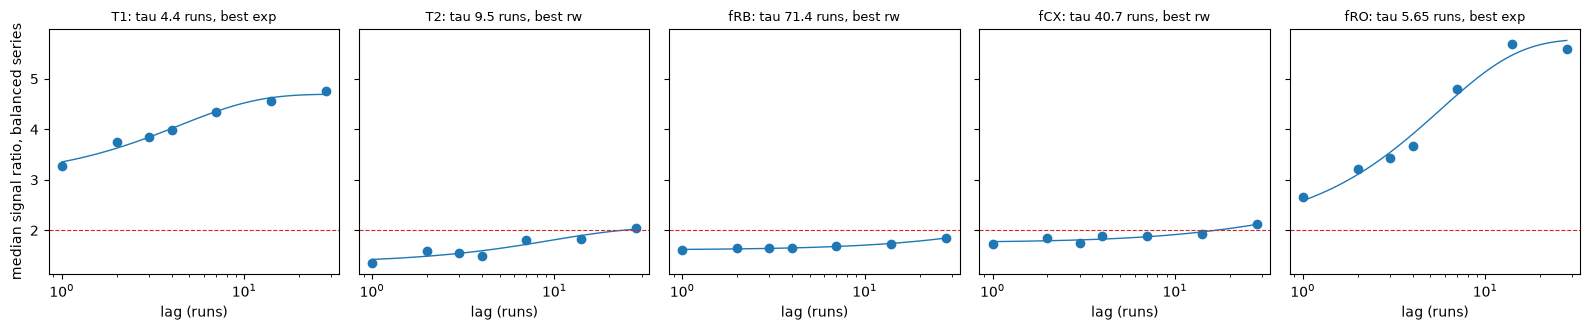

In [4]:
fits = pd.DataFrame({mt: methods.fit_timescale(g.index.get_level_values("lag"), g["ratio_median"].to_numpy())
                     for mt, g in pool_b.groupby(level="metric")}).T
run_days = (pool_b["days_median"] / pool_b.index.get_level_values("lag")).groupby(level="metric").median()
fits["days_per_run"] = run_days
fits["tau_days"] = fits["tau"].astype(float) * run_days
print("timescale fit of the balanced median signal ratio against lag, per metric (c, a in noise units; tau in runs and days);",
      "random walk c + b L; best: lowest AICc of exponential, random walk and constant:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(fits.reindex(METRICS))

per = []
for key, g in sf["ratio"].dropna().groupby(level=SER):
    if len(g) >= 5:
        per.append(dict(zip(SER, key)) | methods.fit_timescale(g.index.get_level_values("lag"), g.to_numpy()))
per = pd.DataFrame(per)
print("per-series fits (series with a signal ratio at 5+ lags): medians, share with tau at the grid edge, and share per best model by AICc:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(per.groupby("metric").agg(series=("tau", "size"), c=("c", "median"), a=("a", "median"), tau_runs=("tau", "median"),
                                      tau_at_edge=("tau_at_edge", "mean"))
            .join(pd.crosstab(per["metric"], per["best"], normalize="index").add_prefix("best_")).reindex(METRICS))

fig, axes = plt.subplots(1, len(METRICS), figsize=(16, 3.4), sharey=True)
Lg = np.geomspace(1, 28, 100)
for ax, mt in zip(axes, METRICS):
    g = pool_b.xs(mt)
    ax.plot(g.index, g["ratio_median"], "o", color="C0")
    f = fits.loc[mt]
    ax.plot(Lg, f["c"] + f["a"] * (1 - np.exp(-Lg / f["tau"])), color="C0", lw=1)
    ax.axhline(SIGNAL_MIN, color="C3", lw=0.8, ls="--")
    ax.set_xscale("log")
    ax.set_title(f"{mt}: tau {f['tau']:.3g} runs, best {f['best']}", fontsize=9)
    ax.set_xlabel("lag (runs)")
axes[0].set_ylabel("median signal ratio, balanced series")
fig.tight_layout()
out = FIG / "c1_structure_function.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

d = d.join(sers["lstar"], on=SER)
d["block"] = d["metric"].map(block)
d["scan"] = ~d["metric"].map(plateau)
d["min_seg"] = np.maximum(K_MIN, d["lstar"].fillna(K_MIN)).astype(int)
d_pool = d[d["sigma_main"].notna()]  # pooled analyses: every series with a main noise row
print(f"rows for pooled analyses (all entities / censored at most {CENSOR_MAX}):", d_pool.groupby("metric").size().to_dict(),
      d_pool[d_pool["cens_ok"]].groupby("metric").size().to_dict())
print(f"rows for per-element analyses (series with an L*; all entities / censored at most {CENSOR_MAX}):",
      d_pool[d_pool["lstar"].notna()].groupby("metric").size().to_dict(),
      d_pool[d_pool["lstar"].notna() & d_pool["cens_ok"]].groupby("metric").size().to_dict())

**Results.**

- An exponential fits best for T1 ($\tau$ 4.4 runs) and fRO (5.65), and a random walk for T2, fCX and fRB. No $\tau$ hits the grid edge, and runs are a median 1 day apart, so runs are roughly days here.
- $c$ is above 1 for every metric (1.35 for T2 up to 3.01 for T1), so each one scatters from run to run by more than its noise row says, before any drift. That means $L^* = 1$ flags this extra scatter, not drift - for drift we look at $a$ and $V_L$.
- Per series it's noisier: the constant fits best on half (fRO) to most (fRB) of them.

## 3. Drift within strata

Before testing drift, we need to know whether the elements move together, since that decides what counts as an independent sample. Per metric and stratum we build a chip-wide series - the median over elements of $\log_{10} x$, centred per series, on runs with 5+ elements - and compare its spread with the elements' own:

$$s = \left(\frac{\operatorname{rsd}(\text{chip-wide series})}{\operatorname{median}\ \operatorname{rsd}(\text{centred series})}\right)^2.$$

Even unrelated elements give $s \approx \pi / 2N$, so the null shifts each element's series circularly by a random offset (200 draws, `methods.common_mode_share`). That keeps each series' autocorrelation but breaks the alignment between elements.

In [5]:
pct = lambda s: 10 ** (30 * s) - 1
order = lambda i: i.map(series.stratum_order) if i.name == "stratum" else i


def centred_chip(df: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """The rows with lx_c (log10 x centred per series), and the chip-wide series: per metric, stratum and run, the
    median of lx_c over elements (runs with 5+ elements)."""
    x = df.assign(lx_c=df["lx"] - df.groupby(SER)["lx"].transform("median"))
    c = x.groupby(["metric", "stratum", "run"]).agg(t=("t", "min"), y=("lx_c", "median"), units=("unit", "nunique")).reset_index()
    return x, c[c["units"] >= MIN_UNITS].reset_index(drop=True)


dc, chip = centred_chip(d_pool[d_pool["cens_ok"]])
cm = []
for (mt, st), g in dc.groupby(["metric", "stratum"]):
    if len(chip[(chip["metric"] == mt) & (chip["stratum"] == st)]) < MIN_N:
        continue
    m = g.pivot_table(index="run", columns="unit", values="lx_c")
    cm.append({"metric": mt, "stratum": st, "runs": len(m), "elements": m.shape[1]} | methods.common_mode_share(m, MIN_UNITS))
cm = pd.DataFrame(cm).set_index(["metric", "stratum"]).sort_index(key=order)
print("common mode: (robust sd of the chip-wide series / median per-series robust sd)^2 (centred log10 x), against its value",
      "with each element's series shifted circularly by its own random offset (200 draws; unrelated elements give about pi / 2N):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(cm)

common mode: (robust sd of the chip-wide series / median per-series robust sd)^2 (centred log10 x), against its value with each element's series shifted circularly by its own random offset (200 draws; unrelated elements give about pi / 2N):


runs  elements  share  null_median  null_q95  excess       p
metric stratum                                                                                      
T1     2 (2024-09-18)                     99        22 0.0509       0.0533    0.0765   0.956   0.562
       7 (2025-03-28)                     97        22 0.0349       0.0522    0.0817   0.669    0.96
       8 (2025-07-07)                     40        22 0.0323        0.041    0.0653   0.787   0.731
       9 (2025-08-22)                    180        22 0.0883       0.0714    0.0985    1.24   0.159
       11 (2026-03-24)                    43        22 0.0604       0.0494    0.0877    1.22   0.279
       13 (2026-05-25)                    83        22  0.103       0.0705      0.11    1.46   0.104
T2     2 (2024-09-18)                     99        14  0.137        0.079     0.135    1.73  0.0547
       7 (2025-03-28)                     97        14 0.0923       0.0819     0.111    1.13   0.279
       8 (2025-07-07)                     40        13 0.0886        0.075     0.136    1.18   0.338
       9 (2025-08-22)                    180        14  0.199       0.0335    0.0552    5.93 0.00498
       11 (2026-03-24)                    43        14  0.157         0.06     0.111    2.61 0.00498
       13 (2026-05-25)                    83        14 0.0542       0.0417    0.0743     1.3   0.269
fCX    8 (2025-07-07)                     40        22  0.103       0.0523     0.099    1.97  0.0299
       9 (2025-08-22)                    179        25  0.114       0.0496    0.0678    2.31 0.00498
       11 (2026-03-24)                    43        19  0.221       0.0679     0.129    3.26 0.00498
       13 (2026-05-25) RB from 2026-06    77        20  0.226       0.0713     0.124    3.17 0.00498
fRB    2 (2024-09-18)                     99        24 0.0461       0.0461    0.0644       1   0.502
       7 (2025-03-28)                     97        24 0.0481       0.0551    0.0757   0.873   0.741
       8 (2025-07-07)                     40        24 0.0496       0.0445    0.0892    1.11   0.443
       9 (2025-08-22)                    180        24 0.0858       0.0564    0.0735    1.52 0.00498
       11 (2026-03-24)                    43        24  0.106       0.0581      0.11    1.82  0.0647
       13 (2026-05-25) RB from 2026-06    76        24 0.0647       0.0645    0.0983       1   0.498
fRO    1 (2024-05-28)                     69        32  0.036        0.037    0.0579   0.974   0.542
       2 (2024-09-18)                     99        32 0.0249       0.0251    0.0382   0.989   0.507
       7 (2025-03-28)                     97        32 0.0305       0.0241    0.0371    1.26   0.229
       8 (2025-07-07)                     40        32 0.0789       0.0255    0.0487    3.09 0.00498
       9 (2025-08-22)                    180        32  0.301       0.0503    0.0785    5.99 0.00498
       11 (2026-03-24)                    43        32  0.227       0.0368     0.074    6.18 0.00498
       13 (2026-05-25)                    83        32  0.266       0.0284    0.0556    9.37 0.00498

**Results.**

- Elements clearly move together in most strata: $s$ beats its null at the $p$ floor (0.005) in T2 strata 9 and 11, fCX 9, 11 and 13, fRB 9 and fRO 8, 9, 11 and 13, by 1.5 to 9.4 times. T1 is the exception - no stratum beats its null.

So a bootstrap over elements would understate the uncertainty, and the evidence for drift has to come from the one chip-wide series per stratum, with its runs as the sample. `methods.chip_trend` fits it against time by Theil–Sen and OLS, with the OLS interval

$$\hat\beta \pm c_{95}\, \text{SE}_\text{NW},$$

where $\text{SE}_\text{NW}$ is the Newey–West error at the metric's block and $c_{95}$ is simulated for the series' length and bandwidth (`methods.hac_crit`). Slopes read as percent per 30 days, and up means longer T1 and T2 or more infidelity. Per-element trends ride along as descriptive columns.

drift per metric and stratum (entities censored at most 0.1): chip-wide series (median over elements of centred log10 x per run), Theil-Sen and OLS change per 30 days, OLS interval with the simulated critical value for its runs and bandwidth; per-element columns are descriptive:


runs  blocks  pct_30d  ols_pct_30d    ci_lo     ci_hi        z  crit  excludes_0  elements  element_pct_30d  share_up  elements_lstar  share_abs_z_gt_crit
metric stratum                                                                                                                                                                                    
T1     2 (2024-09-18)                     99    7.07   0.0124       0.0143  0.00288    0.0258     3.59  2.86        True        22        -0.000114       0.5              22                0.227
       7 (2025-03-28)                     97    6.93  0.00304      0.00298 -0.00778    0.0138    0.788  2.86       False        22          0.00553     0.545              22                    0
       8 (2025-07-07)                     40    2.86  0.00842       0.0135  -0.0142     0.042     1.83  3.79       False        22          0.00109       0.5              22                0.136
       9 (2025-08-22)                    180    12.9   0.0123       0.0124  0.00804    0.0167     7.28  2.53        True        22           0.0177     0.773              22                0.409
       11 (2026-03-24)                    43    3.07  0.00657    -0.000134  -0.0511    0.0536 -0.00949   3.7       False        22         0.000774       0.5              22                0.136
       13 (2026-05-25)                    83    5.93  -0.0303      -0.0312  -0.0607 -0.000765    -3.08  3.01        True        22           -0.023     0.318              21                0.238
T2     2 (2024-09-18)                     99    7.07  0.00266      -0.0277  -0.0979    0.0481    -1.07  2.86       False        14         -0.00918     0.429               7                0.143
       7 (2025-03-28)                     97    6.93 -0.00347     0.000744  -0.0229     0.025   0.0888  2.86       False        14          0.00748     0.571              10                    0
       8 (2025-07-07)                     40    2.86   0.0237       0.0325  -0.0137    0.0808     2.65  3.79       False        13           0.0124     0.538               9                0.222
       9 (2025-08-22)                    180    12.9   0.0379       0.0425   0.0291    0.0561     8.14  2.53        True        14           0.0309     0.857              12                0.583
       11 (2026-03-24)                    43    3.07   0.0329       0.0302  -0.0795     0.153    0.976   3.7       False        14           0.0267     0.571              12                 0.25
       13 (2026-05-25)                    81    5.79  -0.0421      -0.0507  -0.0814   -0.0189    -4.76  3.01        True        14          -0.0387     0.286              13                0.385
fCX    8 (2025-07-07)                     40    2.86  -0.0709      -0.0696   -0.117   -0.0192    -5.19  3.79        True        22          -0.0777     0.273              16                0.188
       9 (2025-08-22)                    179    12.8  -0.0218      -0.0219  -0.0259   -0.0178      -13  2.45        True        25          -0.0134      0.12              14                0.429
       11 (2026-03-24)                    43    3.07  -0.0567      -0.0458   -0.115    0.0287    -2.31   3.7       False        19          -0.0464     0.211              18               0.0556
       13 (2026-05-25) RB from 2026-06    77     5.5   0.0547       0.0555   0.0368    0.0745     9.25  3.06        True        20           0.0565       0.9              17                0.588
fRB    2 (2024-09-18)                     99    49.5   0.0029      0.00814  -0.0116    0.0282    0.878  2.14       False        24         -0.00221     0.458              13                0.615
       7 (2025-03-28)                     97    48.5  0.00286    -0.000235   -0.017    0.0168    -0.03  2.16       False        24          -0.0149     0.333              17                0.176
       8 (2025-07-07)                     40      20  0.00985      0.00982  -0.0381    0.0602    0.479  2.38       False        24          

with all entities, metric-strata whose interval excludes 0:


runs  blocks  pct_30d  ols_pct_30d   ci_lo    ci_hi     z  crit
metric stratum                                                                                         
T1     9 (2025-08-22)                    180    12.9    0.013       0.0132 0.00866   0.0178  7.37  2.53
T2     9 (2025-08-22)                    180    12.9   0.0186       0.0199  0.0143   0.0256     9  2.53
       11 (2026-03-24)                    43    3.07   0.0617       0.0617 0.00603     0.12  4.11   3.7
       13 (2026-05-25)                    83    5.93  -0.0494      -0.0516 -0.0872  -0.0146 -4.16  3.01
fCX    8 (2025-07-07)                     40    2.86  -0.0772      -0.0737  -0.106  -0.0406 -8.28  3.79
       9 (2025-08-22)                    179    12.8  -0.0202      -0.0204 -0.0245  -0.0164 -12.3  2.45
       13 (2026-05-25) RB from 2026-06    77     5.5   0.0561       0.0581  0.0409   0.0755  10.5  3.06
fRB    9 (2025-08-22)                    179    89.5  -0.0139      -0.0141 -0.0204 -0.00772  -4.6  2.09
       13 (2026-05-25) RB from 2026-06    76      38   0.0346       0.0383  0.0138   0.0635  3.43  2.18
fRO    9 (2025-08-22)                    180    6.43  -0.0175      -0.0174 -0.0224  -0.0123 -10.2  2.99
       13 (2026-05-25)                    83    2.96   0.0452       0.0417  0.0135   0.0708  5.76  3.88

saved docs/figures/eda/c1_drift.png


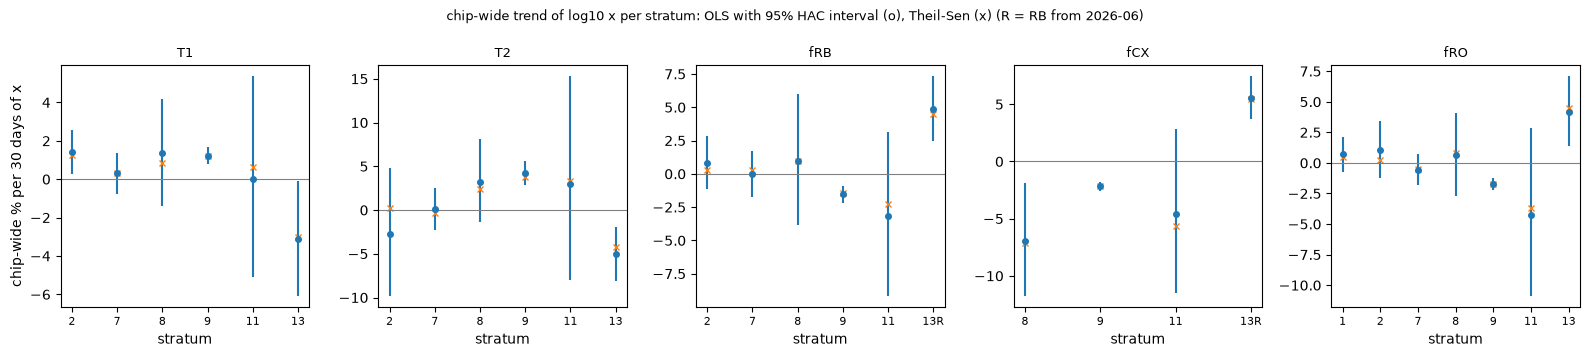

In [6]:
tr = methods.series_trends(d_pool, SER, col="lx").join(sers[["lstar", "cens_ok"]], on=SER)


def chip_drift(c: pd.DataFrame, el: pd.DataFrame) -> pd.DataFrame:
    """Per metric and stratum (20+ runs): chip-wide trend (methods.chip_trend, bandwidth the metric's block) in percent per
    30 days, with the per-element Theil-Sen median, share up and share of |z| beyond its critical value (series with an L*)."""
    rows = []
    for (mt, st), g in c.groupby(["metric", "stratum"]):
        if len(g) < MIN_N:
            continue
        r = methods.chip_trend(g["t"], g["y"], block[mt])
        e = el[(el["metric"] == mt) & (el["stratum"] == st)]
        e_l = e[e["lstar"].notna()]
        rows.append({"metric": mt, "stratum": st, "runs": r["runs"], "blocks": r["blocks"], "pct_30d": pct(r["ts_slope"]),
                     "ols_pct_30d": pct(r["ols_slope"]), "ci_lo": pct(r["lo"]), "ci_hi": pct(r["hi"]), "z": r["z"], "crit": r["crit"],
                     "ols_slope": r["ols_slope"], "se": r["se"], "elements": len(e), "element_pct_30d": pct(e["ts_slope"].median()),
                     "share_up": (e["ts_slope"] > 0).mean(), "elements_lstar": len(e_l),
                     "share_abs_z_gt_crit": (e_l["z"].abs() > e_l["crit"]).mean() if len(e_l) else np.nan})
    out = pd.DataFrame(rows).set_index(["metric", "stratum"]).sort_index(key=order)
    return out.assign(excludes_0=(out["ci_lo"] > 0) | (out["ci_hi"] < 0))


main = chip_drift(chip, tr[tr["cens_ok"]])
sens = chip_drift(centred_chip(d_pool)[1], tr)
cols = ["runs", "blocks", "pct_30d", "ols_pct_30d", "ci_lo", "ci_hi", "z", "crit", "excludes_0", "elements", "element_pct_30d",
        "share_up", "elements_lstar", "share_abs_z_gt_crit"]
print(f"drift per metric and stratum (entities censored at most {CENSOR_MAX}): chip-wide series (median over elements of centred",
      "log10 x per run), Theil-Sen and OLS change per 30 days, OLS interval with the simulated critical value for its runs and",
      "bandwidth; per-element columns are descriptive:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(main[cols])
    print("with all entities, metric-strata whose interval excludes 0:")
    display(sens.loc[sens["excludes_0"], ["runs", "blocks", "pct_30d", "ols_pct_30d", "ci_lo", "ci_hi", "z", "crit"]])

fig, axes = plt.subplots(1, len(METRICS), figsize=(16, 3.6), sharey=False)
for ax, mt in zip(axes, METRICS):
    g = main.xs(mt).reset_index()
    x = np.arange(len(g))
    ax.errorbar(x, 100 * g["ols_pct_30d"], yerr=[100 * (g["ols_pct_30d"] - g["ci_lo"]), 100 * (g["ci_hi"] - g["ols_pct_30d"])], fmt="o", ms=4)
    ax.plot(x, 100 * g["pct_30d"], "x", color="C1", ms=5)
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xticks(x, [s.split()[0] + ("R" if "RB from" in s else "") for s in g["stratum"]], fontsize=8)
    ax.set_title(mt, fontsize=9)
    ax.set_xlabel("stratum")
axes[0].set_ylabel("chip-wide % per 30 days of x")
fig.suptitle("chip-wide trend of log10 x per stratum: OLS with 95% HAC interval (o), Theil-Sen (x) (R = RB from 2026-06)", fontsize=9)
fig.tight_layout()
out = FIG / "c1_drift.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- Intervals exclude 0 in strata 9 and 13 for every metric, and in fCX stratum 8 and T1 stratum 2 - but with opposite signs. T2, for instance, rises +4.25% per 30 days in stratum 9 and falls −5.07% in stratum 13.
- Only fRB reaches 30 blocks in any stratum; the other metrics have 1.4 to 12.9.
- Adding the high-censoring entities back barely changes this: T1 strata 2 and 13 now include 0, and T2 stratum 11 excludes it.

The catch is that strata 2, 9 and 13 also hold the chip-wide change points of section 5, and a straight line can't tell a step from a slope. We come back to this there.

## 4. Level steps at breaks

Now the breaks themselves. Per element, the step is the median of the first $K$ runs after a boundary minus the median of the last $K$ before it (`methods.adjacent_steps`), with $K = \max(7, L_\text{var})$, and the chip-wide step is the median over elements. `SETTLING` is left out, so the thermal cycle is the 9 → 11 step. The gating-era breaks (7 → 8, 8 → 9) act as a check - they should show nothing.

A boundary spans a data gap, and a wandering series moves more over a longer gap, so we judge each step against a placebo with the same gap: the same window steps at every split inside a stratum (`methods.placebo_steps`). We test both the size, $|\text{median step}|$, and the direction, $|\text{share up} - 0.5|$, with

$$p = \frac{1 + \#\{\text{placebo} \ge \text{observed}\}}{1 + n_\text{placebo}}.$$

The placebo keeps the common mode, so it's the inference here, and the bootstrap over elements is just descriptive. With a few hundred placebo values $p$ can't go below about 0.003, nor the Benjamini–Hochberg $q$ below about 0.08, so placebo_z - the step in robust sd of the placebo - shows how far past that floor a step is.

step window K per metric (runs): {'T1': 7, 'T2': 28, 'fRB': 28, 'fCX': 28, 'fRO': 7}


chip-wide level step between consecutive strata (median over elements; bootstrap interval over elements, descriptive only). Placebo: within-stratum window steps spanning the boundary's median gap; placebo_p for |median step| (magnitude), direction_p for |share up - 0.5| (a common direction), both (1 + placebo values at least as large) / (1 + placebo values), q: Benjamini-Hochberg over the boundaries (p cannot fall below 1 / (1 + placebo_n)); placebo_z: step in robust sd of the placebo medians; beyond_own_q95: share of elements whose |step| passes their own 95% placebo quantile (0.05 under no step):


elements  gap_days  delta_log10    ci_lo    ci_hi       pct  share_up  placebo_n  placebo_p  placebo_q  placebo_z  direction_p  direction_q  beyond_own_q95 last_before first_after  \
metric stratum_before  stratum_after                                                                                                                                                                                                          
T1     11 (2026-03-24) 13 (2026-05-25)                        22      7.99      -0.0107  -0.0338   0.0474   -0.0244     0.409        390      0.532      0.961     -0.678        0.455            1          0.0455  2026-05-18  2026-05-26   
       2 (2024-09-18)  7 (2025-03-28)                         22        52     -0.00433  -0.0906   0.0681  -0.00993       0.5        199      0.835      0.961     -0.341            1            1           0.136  2025-02-04  2025-03-28   
       7 (2025-03-28)  8 (2025-07-07)                         22         1      -0.0128  -0.0463   0.0083   -0.0289     0.409        331      0.431      0.961     -0.871        0.497            1          0.0455  2025-07-06  2025-07-07   
       8 (2025-07-07)  9 (2025-08-22)                         22         3      -0.0147  -0.0419   0.0259   -0.0334     0.364        367       0.41      0.961     -0.841        0.321            1          0.0455  2025-08-19  2025-08-22   
       9 (2025-08-22)  11 (2026-03-24)                        22        27     -0.00499  -0.0338    0.024   -0.0114     0.455        278      0.771      0.961       -0.4        0.717            1          0.0455  2026-03-08  2026-04-04   
T2     11 (2026-03-24) 13 (2026-05-25)                        14      7.99       0.0466  0.00515    0.113     0.113     0.714        193     0.0567      0.667       2.12        0.407            1          0.0714  2026-05-18  2026-05-26   
       2 (2024-09-18)  7 (2025-03-28)                         14        52      -0.0553   -0.071     0.15     -0.12     0.286         67      0.544      0.961      -4.13        0.603            1             0.5  2025-02-04  2025-03-28   
       7 (2025-03-28)  8 (2025-07-07)                         13         1      -0.0226   -0.027 -0.00794   -0.0507     0.154        168      0.266      0.961      -1.95       0.0828        0.994          0.0769  2025-07-06  2025-07-07   
       8 (2025-07-07)  9 (2025-08-22)                         13         3      0.00541 -0.00015   0.0249    0.0125     0.692        185      0.699      0.961     -0.186        0.446            1               0  2025-08-19  2025-08-22   
       9 (2025-08-22)  11 (2026-03-24)                        14        27      -0.0169   -0.166   0.0202   -0.0382     0.357        127      0.492      0.961      -1.25        0.562            1           0.429  2026-03-08  2026-04-04   
fCX    11 (2026-03-24) 13 (2026-05-25) RB from 2026-06        19        14      -0.0276  -0.0678   0.0156   -0.0616     0.421        108     0.0917      0.667       -1.9        0.908            1           0.316  2026-05-18  2026-06-01   
       8 (2025-07-07)  9 (2025-08-22)                         22         3      0.00103 -0.00953   0.0127   0.00238       0.5        110      0.982      0.994       1.23            1            1          0.0455  2025-08-19  2025-08-22   
       9 (2025-08-22)  11 (2026-03-24)                        17        27       0.0105  -0.0384     0.19    0.0245     0.529         87      0.841      0.961       3.54        0.977            1           0.529  2026-03-08  2026-04-04   
fRB    11 (2026-03-24) 13 (2026-05-25) RB from 2026-06        24        14      -0.0116  -0.0305   0.0258   -0.0263     0.458        156      0.439      0.961     -0.552        0.732            1           0.167  2026-05-18  2026-06-01   
       2 (2024-09-18)  7 (2025-03-28)                         24        53       -0.018  -0.0782   0.0802   -0.0406       0.5         66      0.612      0.961     -0.204            1            1           0.583  2025-02-04  2025-03

saved docs/figures/eda/c1_break_steps.png


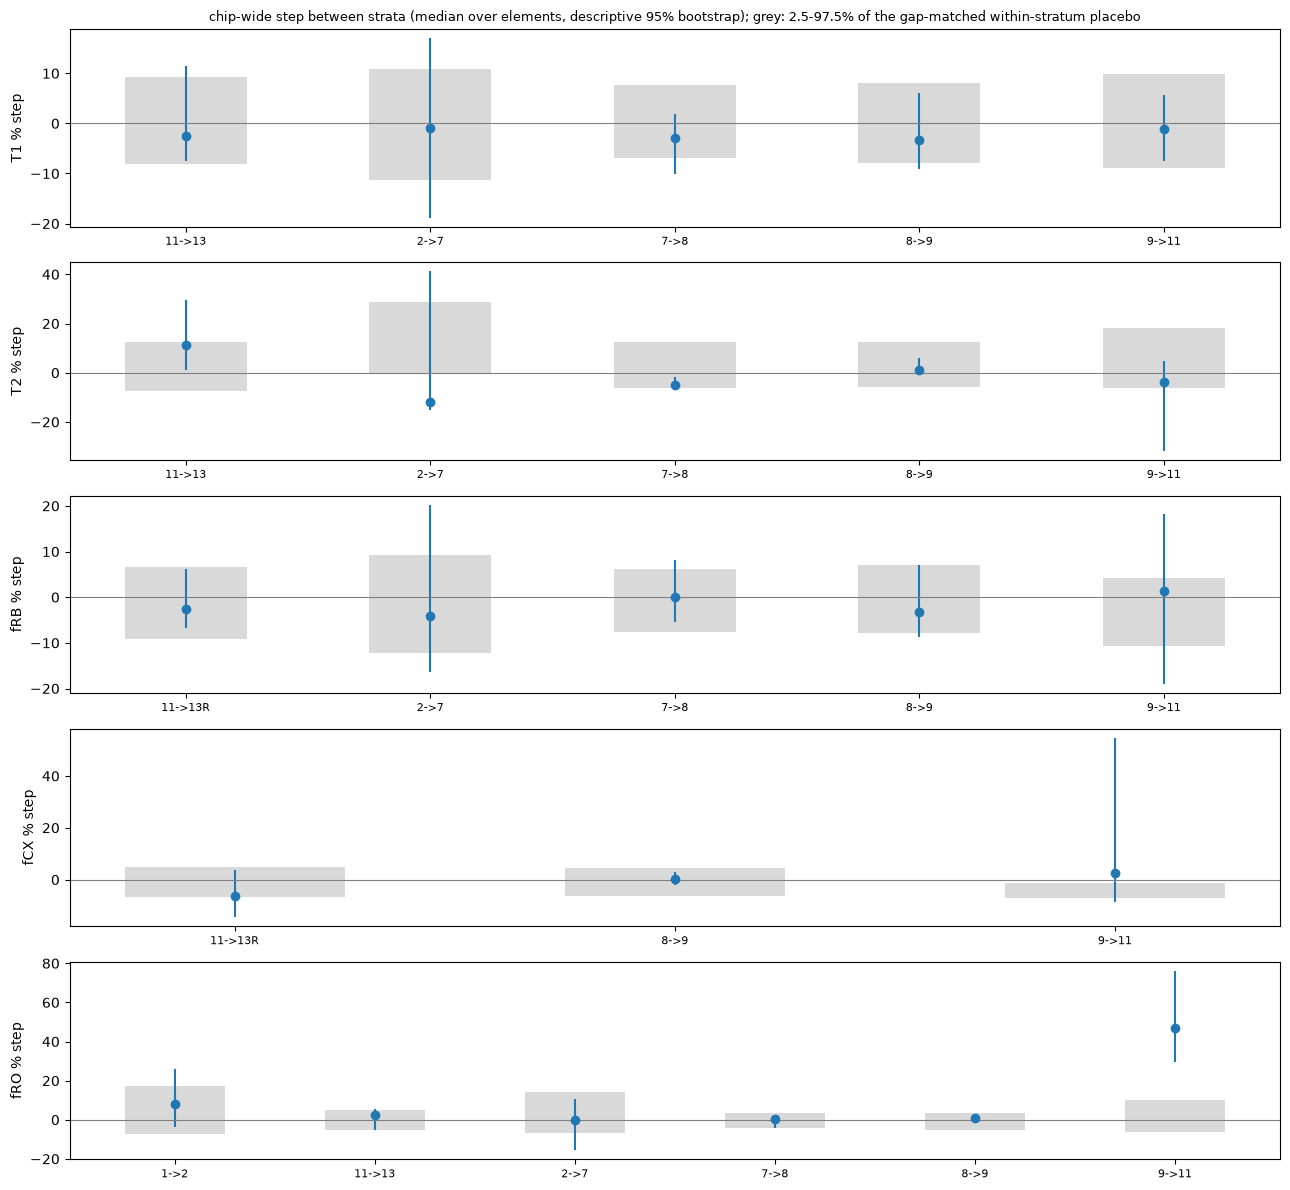

In [7]:
K = {mt: int(max(K_MIN, lvar[mt] if pd.notna(lvar[mt]) else max(LAGS))) for mt in METRICS}
print("step window K per metric (runs):", K)
dp = d_pool[d_pool["cens_ok"] & (d_pool["stratum"] != "settling")]
steps = pd.concat([methods.adjacent_steps(dp[dp["metric"] == mt], ["metric", "unit"], K[mt], col="lx") for mt in METRICS],
                  ignore_index=True)
BND = ["metric", "stratum_before", "stratum_after"]


def between(a: pd.Timestamp, b: pd.Timestamp) -> str:
    """Register entries in (a, b]: breaks by date and what, other events by type."""
    e = EV[(EV["at"] > a) & (EV["at"] <= b)]
    brk = e.loc[e["type"] == "BREAK", "label"].str.removeprefix("BREAK ").tolist()
    other = e.loc[e["type"] != "BREAK", "type"].value_counts().to_dict()
    return "; ".join(brk) + (f" | {other}" if other else "")


def placebo(mt: str, gap: pd.Timedelta) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Within-stratum placebo for metric mt with the boundary's gap: per-element steps, and per split time the
    chip-wide median and share up (5+ elements)."""
    pl = methods.placebo_steps(dp[dp["metric"] == mt], SER, K[mt], col="lx", gap=gap)
    pc = pl.groupby(["stratum", "t"])["step"].agg(median="median", up=lambda s: (s > 0).mean(), size="size")
    return pl, pc[pc["size"] >= MIN_UNITS]


rows = []
for (mt, sb, sa), g in steps.groupby(BND):
    if len(g) < MIN_UNITS:
        continue
    a, b, gap = g["t_before"].median(), g["t_after"].median(), (g["t_after"] - g["t_before"]).median()
    pl, pc = placebo(mt, gap)
    med, lo, hi = methods.bootstrap_median(g["delta"])
    up = (g["delta"] > 0).mean()
    q95 = pl.assign(a=pl["step"].abs()).groupby("unit")["a"].quantile(0.95)
    has_q = g["unit"].isin(q95.index)
    pl_lo, pl_hi = np.quantile(pc["median"], [0.025, 0.975]) if len(pc) else (np.nan, np.nan)
    rows.append({"metric": mt, "stratum_before": sb, "stratum_after": sa, "elements": len(g), "gap_days": gap / pd.Timedelta("1D"),
                 "delta_log10": med, "ci_lo": lo, "ci_hi": hi, "pct": 10 ** med - 1, "share_up": up, "placebo_n": len(pc),
                 "placebo_p": methods.perm_p(pc["median"].abs(), abs(med)),
                 "placebo_z": (med - pc["median"].median()) / methods.rsd(pc["median"]) if len(pc) >= 3 else np.nan,
                 "direction_p": methods.perm_p((pc["up"] - 0.5).abs(), abs(up - 0.5)),
                 "beyond_own_q95": float((g.loc[has_q, "delta"].abs() > g.loc[has_q, "unit"].map(q95)).mean()) if has_q.any() else np.nan,
                 "pl_lo": pl_lo, "pl_hi": pl_hi, "last_before": a.strftime("%Y-%m-%d"), "first_after": b.strftime("%Y-%m-%d"),
                 "between": between(a, b)})
bs = pd.DataFrame(rows).set_index(BND)
bs["placebo_q"] = methods.bh(bs["placebo_p"])
bs["direction_q"] = methods.bh(bs["direction_p"])
print("chip-wide level step between consecutive strata (median over elements; bootstrap interval over elements, descriptive only).",
      "Placebo: within-stratum window steps spanning the boundary's median gap; placebo_p for |median step| (magnitude),",
      "direction_p for |share up - 0.5| (a common direction), both (1 + placebo values at least as large) / (1 + placebo values),",
      "q: Benjamini-Hochberg over the boundaries (p cannot fall below 1 / (1 + placebo_n)); placebo_z: step in robust sd of the placebo",
      "medians; beyond_own_q95: share of elements whose |step| passes their own 95% placebo quantile (0.05 under no step):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(bs[["elements", "gap_days", "delta_log10", "ci_lo", "ci_hi", "pct", "share_up", "placebo_n", "placebo_p", "placebo_q", "placebo_z",
                "direction_p", "direction_q", "beyond_own_q95", "last_before", "first_after", "between"]])

fig, axes = plt.subplots(len(METRICS), 1, figsize=(13, 12), sharex=False)
for ax, mt in zip(axes, METRICS):
    if mt not in bs.index.get_level_values("metric"):
        continue
    g = bs.xs(mt).reset_index()
    x = np.arange(len(g))
    ax.bar(x, 100 * ((10 ** g["pl_hi"] - 1) - (10 ** g["pl_lo"] - 1)), bottom=100 * (10 ** g["pl_lo"] - 1), width=0.5, color="0.85", zorder=0)
    ax.errorbar(x, 100 * g["pct"], yerr=[100 * (g["pct"] - (10 ** g["ci_lo"] - 1)), 100 * ((10 ** g["ci_hi"] - 1) - g["pct"])], fmt="o")
    ax.axhline(0, color="0.5", lw=0.8)
    ax.set_xticks(x, [f"{a.split()[0]}->{b.split()[0]}{'R' if 'RB from' in b else ''}" for a, b in zip(g["stratum_before"], g["stratum_after"])], fontsize=8)
    ax.set_ylabel(f"{mt} % step")
axes[0].set_title("chip-wide step between strata (median over elements, descriptive 95% bootstrap); grey: 2.5-97.5% of the gap-matched within-stratum placebo", fontsize=9)
fig.tight_layout()
out = FIG / "c1_break_steps.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- The thermal cycle stands out for fRO: +46.9%, with 0.875 of qubits up, placebo_z 15.0 and $p$ at its floor ($q$ 0.0782).
- Nothing else comes close. Next are T2 11 → 13 (+11.3%) and fCX 11 → 13 (−6.16%), both at $q$ 0.667, and the other metrics barely move at the thermal cycle (−3.82% to +2.45%, $p$ 0.49 to 0.84).
- The gating-era breaks show nothing ($p$ 0.27 to 0.99), as they should.

## 5. Change points

Last, steps that don't sit at a break. Per series with an $L^*$, we run binary segmentation on $\log_{10} x$ (`methods.binary_segmentation`) with the CUSUM statistic

$$T = \frac{\max_k |S_k|}{\sigma_\text{LR}\sqrt n},$$

where $S_k$ is the running sum of deviations from the segment mean and $\sigma_\text{LR}$ the long-run sd at the metric's block. A wide bandwidth pulls $\sigma_\text{LR}$ low, so each segment gets its own simulated 95% critical value (`methods.cusum_crit`) instead of the textbook 1.358. Segments keep at least $\max(7, L^*)$ runs per element and $K$ chip-wide.

A random-walk-like series fails any CUSUM test, so metrics with no plateau (block 28) get the jump scan instead (`methods.scan_jumps`), which checks $K$-run window steps against a random walk. We flag a change point at the first or last split allowed as an *edge*, since the real change could sit anywhere nearer that end.

We match change points to register events within 2 days, against the chance rate over all eligible times, and fCX also to its own list switches.

In [8]:
de = d_pool[d_pool["lstar"].notna() & d_pool["cens_ok"]]
cp, elig = methods.change_points(de, SER, col="lx", scan_col="scan")
cp["near"] = methods.near(cp["t"], EV["at"], NEAR_EVENT)
elig["near"] = methods.near(elig["t"], EV["at"], NEAR_EVENT)
cp["event"] = ["; ".join(EV.loc[(EV["at"] - t).abs() <= NEAR_EVENT, "label"]) for t in cp["t"]]
cp["pct"] = 10 ** cp["shift"] - 1
print("per-series change points (CUSUM against its simulated critical value where the metric's variance ratio levels off, else the",
      "jump scan); edge: at the first or last allowed split of the series; matched within 2 days against chance:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(elig.groupby("metric").agg(series=("unit", lambda s: len(elig.loc[s.index, SER].drop_duplicates())), chance=("near", "mean"))
            .join(cp.groupby("metric").agg(change_points=("t", "size"), method=("method", "first"), edge=("edge", "sum"),
                                           series_with=("unit", lambda s: len(cp.loc[s.index, SER].drop_duplicates())),
                                           matched=("near", "mean"), median_abs_pct=("pct", lambda s: s.abs().median())))
            .assign(matched_over_chance=lambda x: x["matched"] / x["chance"]).reindex(METRICS))

ETYPE = sorted(EV["type"].unique())
bt = []
for ty in ETYPE:
    at = EV.loc[EV["type"] == ty, "at"]
    m = pd.Series(methods.near(cp["t"], at, NEAR_EVENT), index=cp.index).groupby(cp["metric"]).agg(["sum", "mean"])
    c = pd.Series(methods.near(elig["t"], at, NEAR_EVENT), index=elig.index).groupby(elig["metric"]).mean()
    bt.append(m.join(c.rename("chance")).assign(event_type=ty))
bt = pd.concat(bt).rename(columns={"sum": "change_points", "mean": "matched"}).reset_index().set_index(["metric", "event_type"])
bt = bt[(bt["change_points"] > 0) | (bt["chance"] > 0)].assign(matched_over_chance=lambda x: x["matched"] / x["chance"])
print("by event type:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(bt)

fk = kept[kept["metric"] == "fCX"].sort_values(["element", "run"])
sw = fk[(fk["lst"] != fk.groupby("element")["lst"].shift()) & (fk.groupby("element").cumcount() > 0)]
sw_at = sw.groupby("element")["t"].apply(list)
fc = cp[cp["metric"] == "fCX"].assign(element=lambda x: x["unit"].str.split().str[0])
fe = elig[elig["metric"] == "fCX"].assign(element=lambda x: x["unit"].str.split().str[0])
at_sw = lambda f: np.array([methods.near([t], sw_at.get(e, []), NEAR_EVENT)[0] for e, t in zip(f["element"], f["t"])], dtype=bool)
if len(fc):
    print(f"fCX: list switches {len(sw)} on {sw['element'].nunique()} couplings; change points within 2 days of the coupling's own switch",
          f"{at_sw(fc).mean():.3f} of {len(fc)}, against {at_sw(fe).mean():.3f} of eligible times")

per-series change points (CUSUM against its simulated critical value where the metric's variance ratio levels off, else the jump scan); edge: at the first or last allowed split of the series; matched within 2 days against chance:


,series,chance,change_points,method,edge,series_with,matched,median_abs_pct,matched_over_chance
metric,,,,,,,,,
T1,131,0.0477,48,cusum,0,37,0,0.21,0
T2,63,0.0529,31,cusum,2,23,0.0323,0.351,0.609
fRB,91,0.0545,41,cusum,1,36,0,0.351,0
fCX,65,0.0494,26,cusum,0,21,0.0385,0.259,0.779
fRO,213,0.0433,102,scan,12,57,0,0.5,0


by event type:


,,change_points,matched,chance,matched_over_chance
metric,event_type,,,,
T1,DS4_GAP,0,0,0.0192,0
T2,DS4_GAP,0,0,0.0228,0
fCX,DS4_GAP,0,0,0.0327,0
fRB,DS4_GAP,0,0,0.0235,0
fRO,DS4_GAP,0,0,0.0178,0
T1,F01_FLAG,0,0,0.015,0
T2,F01_FLAG,0,0,0.0185,0
fCX,F01_FLAG,0,0,0.0165,0
fRB,F01_FLAG,0,0,0.021,0


fCX: list switches 1130 on 32 couplings; change points within 2 days of the coupling's own switch 0.000 of 26, against 0.061 of eligible times


**Results.**

- Per series, change points match the register no better than chance for any metric (0 to 0.0385, against 0.043 to 0.055).
- None of the 26 fCX change points sits at the coupling's own list switch (0.061 by chance).
- fRO's jump scan puts 12 of its 102 change points at an edge, against 1 or none for the other metrics.

Then the same search on the chip-wide series of section 3.

chip-wide series: runs with 5+ elements per metric: {'T1': 542, 'T2': 540, 'fCX': 339, 'fRB': 534, 'fRO': 611}
chip-wide change points (first run after the split, statistic and its critical value, step in percent, edge, register events within 2 days):


,metric,stratum,t,method,stat,crit,pct,edge,event
0,T1,2 (2024-09-18),2024-12-30 20:20,cusum,2.21,1.95,0.0323,False,
1,T1,9 (2025-08-22),2025-12-22 20:14,cusum,3.81,1.69,0.0562,False,
2,T1,13 (2026-05-25),2026-08-01 20:02,cusum,2.71,1.99,-0.0812,False,
3,T1,13 (2026-05-25),2026-08-26 21:47,cusum,3.3,3.12,-0.0695,False,
4,T2,9 (2025-08-22),2025-10-21 20:14,cusum,2.48,1.82,0.0663,False,
5,T2,9 (2025-08-22),2025-12-21 20:13,cusum,3.68,1.69,0.188,False,
6,T2,13 (2026-05-25),2026-07-30 20:14,cusum,2.31,1.86,-0.108,True,
7,fCX,9 (2025-08-22),2025-10-05 20:13,cusum,2.58,1.85,-0.0386,False,
8,fCX,9 (2025-08-22),2025-12-15 20:13,cusum,3.85,1.7,-0.0817,False,
9,fCX,13 (2026-05-25) RB from 2026-06,2026-07-12 19:59,cusum,5.33,1.91,0.119,False,


matched share against chance:


,size,mean,chance
metric,,,
T1,4,0,0.0496
T2,3,0,0.0422
fCX,3,0,0.0205
fRB,2,0,0.0303
fRO,1,0,0.0442


saved docs/figures/eda/c1_chip_series.png


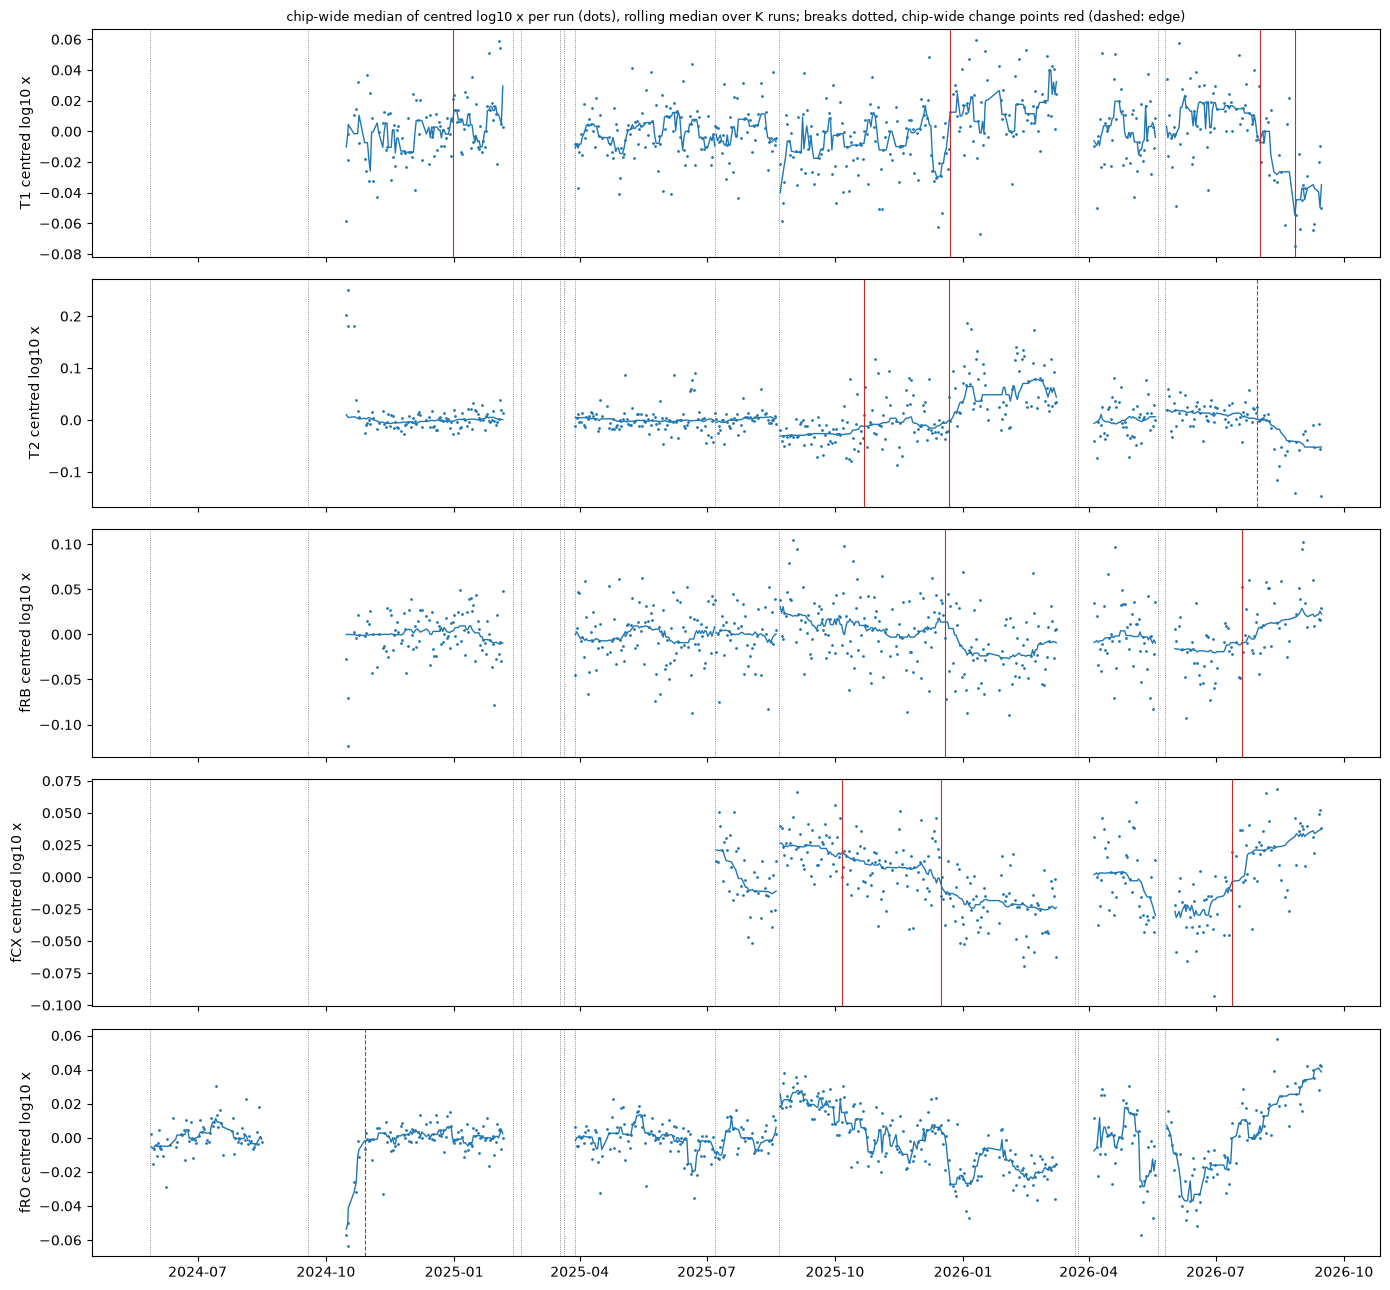

In [9]:
chip["block"] = chip["metric"].map(block)  # chip: the section 3 chip-wide series (censored at most 10%, 5+ elements per run)
chip["min_seg"] = chip["metric"].map(K)
chip["scan"] = ~chip["metric"].map(plateau)
ccp, celig = methods.change_points(chip, ["metric", "stratum"], col="y", scan_col="scan")
ccp["near"] = methods.near(ccp["t"], EV["at"], NEAR_EVENT)
ccp["event"] = ["; ".join(EV.loc[(EV["at"] - t).abs() <= NEAR_EVENT, "label"]) for t in ccp["t"]]
ccp["pct"] = 10 ** ccp["shift"] - 1
celig["near"] = methods.near(celig["t"], EV["at"], NEAR_EVENT)
print("chip-wide series: runs with 5+ elements per metric:", chip.groupby("metric").size().to_dict())
print("chip-wide change points (first run after the split, statistic and its critical value, step in percent, edge,",
      "register events within 2 days):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ccp.sort_values(["metric", "t"]).assign(t=lambda x: x["t"].dt.strftime("%Y-%m-%d %H:%M"))
            [["metric", "stratum", "t", "method", "stat", "crit", "pct", "edge", "event"]].reset_index(drop=True))
    print("matched share against chance:")
    display(ccp.groupby("metric")["near"].agg(["size", "mean"]).join(celig.groupby("metric")["near"].mean().rename("chance")))

fig, axes = plt.subplots(len(METRICS), 1, figsize=(14, 13), sharex=True)
for ax, mt in zip(axes, METRICS):
    g = chip[chip["metric"] == mt]
    for _, s in g.groupby("stratum"):
        ax.plot(s["t"], s["y"], ".", ms=2, color="C0")
        ax.plot(s["t"], s["y"].rolling(K[mt], center=True, min_periods=3).median(), color="C0", lw=1)
    for b in periods.BREAKS:
        ax.axvline(b.at, color="0.4", lw=0.6, ls=":")
    for t, e in zip(ccp.loc[ccp["metric"] == mt, "t"], ccp.loc[ccp["metric"] == mt, "edge"]):
        ax.axvline(t, color="C3", lw=0.8, ls="--" if e else "-")
    ax.set_ylabel(f"{mt} centred log10 x")
axes[0].set_title("chip-wide median of centred log10 x per run (dots), rolling median over K runs; breaks dotted, chip-wide change points red (dashed: edge)", fontsize=9)
fig.tight_layout()
out = FIG / "c1_chip_series.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- Chip-wide, T1, T2, fRB and fCX all step in the same two windows, with no register event nearby. From 2025-12-15 to 12-22 (stratum 9) T1 and T2 get longer and the infidelities drop (T2 +18.8%, fCX −8.17%), and from 2026-07-12 to 08-01 (stratum 13) it goes the other way (T2 −10.8%, fCX +11.9%).
- T1 also steps on 2024-12-30 (+3.23%, stratum 2), with no register event nearby.
- fRO's one chip-wide change point is in stratum 2 and at an edge, so it can't be dated.

fRO missing both windows is suspicious, since its block of 28 only just missed the cutoff (section 2) and that's what sent it to the jump scan. So we rerun fRO the way the other metrics get it - CUSUM with a block of 14.

In [10]:
BLOCK_ALT = 14  # runs: fRO's block if its variance ratio is read as levelling off at 14

fro = de[de["metric"] == "fRO"].assign(block=BLOCK_ALT, scan=False)
cp14, elig14 = methods.change_points(fro, SER, col="lx", scan_col="scan")
cp14["near"] = methods.near(cp14["t"], EV["at"], NEAR_EVENT)
elig14["near"] = methods.near(elig14["t"], EV["at"], NEAR_EVENT)
out_at = EV.loc[EV["type"] == "OUTAGE", "at"]
summ = {}
for name, c, e in [("jump scan, block 28", cp[cp["metric"] == "fRO"], elig[elig["metric"] == "fRO"]),
                   (f"CUSUM, block {BLOCK_ALT}", cp14, elig14)]:
    summ[name] = {"series": len(e[SER].drop_duplicates()), "change_points": len(c), "series_with": len(c[SER].drop_duplicates()),
                  "edge": int(c["edge"].sum()), "median_abs_pct": (10 ** c["shift"] - 1).abs().median(),
                  "matched": c["near"].mean(), "chance": e["near"].mean(),
                  "outage_matched": methods.near(c["t"], out_at, NEAR_EVENT).mean(),
                  "outage_chance": methods.near(e["t"], out_at, NEAR_EVENT).mean()}
print(f"fRO per-series change points with the main method and with CUSUM at block {BLOCK_ALT} (matched within 2 days, against chance):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(summ).T)

ccp14, _ = methods.change_points(chip[chip["metric"] == "fRO"].assign(block=BLOCK_ALT, scan=False), ["metric", "stratum"],
                                 col="y", scan_col="scan")
ccp14["pct"] = 10 ** ccp14["shift"] - 1
ccp14["event"] = ["; ".join(EV.loc[(EV["at"] - t).abs() <= NEAR_EVENT, "label"]) for t in ccp14["t"]]
print(f"fRO chip-wide change points with CUSUM at block {BLOCK_ALT} (minimum segment K):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ccp14.sort_values("t").assign(t=lambda x: x["t"].dt.strftime("%Y-%m-%d %H:%M"))
            [["stratum", "t", "stat", "crit", "pct", "edge", "event"]].reset_index(drop=True))

fRO per-series change points with the main method and with CUSUM at block 14 (matched within 2 days, against chance):


,series,change_points,series_with,edge,median_abs_pct,matched,chance,outage_matched,outage_chance
"jump scan, block 28",213,102,57,12,0.5,0,0.0433,0,0
"CUSUM, block 14",213,96,73,3,0.171,0.0208,0.0433,0,0


fRO chip-wide change points with CUSUM at block 14 (minimum segment K):


,stratum,t,stat,crit,pct,edge,event
0,9 (2025-08-22),2025-10-09 20:14,3.59,1.83,-0.0457,False,
1,9 (2025-08-22),2025-12-17 20:14,2.57,1.69,-0.0603,False,
2,11 (2026-03-24),2026-05-07 20:19,3.47,2.53,-0.0678,False,
3,13 (2026-05-25),2026-07-17 20:12,2.82,1.99,0.0908,False,
4,13 (2026-05-25),2026-08-11 20:13,4.61,2.61,0.0523,False,


**Results.**

- Per series, fRO's edge change points drop from 12 to 3 and the steps get smaller (median 17.1% against 50.0%). They match the register below chance (0.0208 against 0.0433).
- Chip-wide, fRO now steps on 2025-12-17 (−6.03%) and 2026-07-17 (+9.08%) - inside both windows and in the same direction as the others - and the stratum 2 edge point is gone.

So all five metrics share the two chip-wide steps. That brings us back to section 3: is the drift in strata 9 and 13 (and T1 stratum 2) real, or just these steps? We refit the chip-wide trend between the change points. The bandwidth comes from the per-element block, so we also refit each whole stratum with bandwidth 28 to be safe.

In [11]:
steps = pd.concat([ccp[ccp["metric"] != "fRO"], ccp14])  # fRO: its block-14 change points
rows = []
for mt, st in main.index[main["excludes_0"]]:
    g = chip[(chip["metric"] == mt) & (chip["stratum"] == st)].sort_values("t")
    at = sorted(steps.loc[(steps["metric"] == mt) & (steps["stratum"] == st), "t"])
    parts = [("whole", g, block[mt])] + ([("whole, bandwidth 28", g, 28)] if block[mt] < 28 else [])
    edges = [g["t"].min(), *at, g["t"].max() + pd.Timedelta("1s")]
    parts += [(f"from {a:%Y-%m-%d}", g[(g["t"] >= a) & (g["t"] < b)], block[mt]) for a, b in zip(edges[:-1], edges[1:])] if at else []
    for name, s, bw in parts:
        r = methods.chip_trend(s["t"], s["y"], bw) if len(s) >= MIN_N else None
        rows.append({"metric": mt, "stratum": st, "part": name, "runs": len(s), "bandwidth": bw,
                     **({"ols_pct_30d": pct(r["ols_slope"]), "ci_lo": pct(r["lo"]), "ci_hi": pct(r["hi"])} if r else {})})
seg = pd.DataFrame(rows)
seg["excludes_0"] = (seg["ci_lo"] > 0) | (seg["ci_hi"] < 0)
print(f"chip-wide drift (as section 3) of every metric-stratum whose interval excludes 0: the whole stratum, the whole stratum",
      f"with bandwidth 28, and each part between its chip-wide change points ({MIN_N}+ runs; fRO with its block-14 change points):")
with pd.option_context("display.float_format", "{:.3g}".format, "display.max_rows", 100):
    display(seg.set_index(["metric", "stratum", "part"]))

chip-wide drift (as section 3) of every metric-stratum whose interval excludes 0: the whole stratum, the whole stratum with bandwidth 28, and each part between its chip-wide change points (20+ runs; fRO with its block-14 change points):


runs  bandwidth  ols_pct_30d    ci_lo     ci_hi  excludes_0
metric stratum                         part                                                                            
T1     2 (2024-09-18)                  whole                  99         14       0.0143  0.00288    0.0258        True
                                       whole, bandwidth 28    99         28       0.0143  0.00299    0.0257        True
                                       from 2024-10-15        62         14      0.00536 -0.00932    0.0203       False
                                       from 2024-12-30        37         14       0.0173  -0.0488    0.0879       False
       9 (2025-08-22)                  whole                 180         14       0.0124  0.00804    0.0167        True
                                       whole, bandwidth 28   180         28       0.0124  0.00743    0.0173        True
                                       from 2025-08-22       115         14      0.00178  -0.0121    0.0158       False
                                       from 2025-12-22        65         14      0.00686  -0.0112    0.0252       False
       13 (2026-05-25)                 whole                  83         14      -0.0312  -0.0607 -0.000765        True
                                       whole, bandwidth 28    83         28      -0.0312  -0.0703   0.00954       False
                                       from 2026-05-26        55         14       0.0135 -0.00379    0.0311       False
                                       from 2026-08-01        15         14          NaN      NaN       NaN       False
                                       from 2026-08-26        13         14          NaN      NaN       NaN       False
T2     9 (2025-08-22)                  whole                 180         14       0.0425   0.0291    0.0561        True
                                       whole, bandwidth 28   180         28       0.0425   0.0307    0.0544        True
                                       from 2025-08-22        58         14      0.00396  -0.0176     0.026       False
                                       from 2025-10-21        56         14      -0.0283  -0.0697    0.0149       False
                                       from 2025-12-21        66         14      0.00965  -0.0509     0.074       False
       13 (2026-05-25)                 whole                  81         14      -0.0507  -0.0814   -0.0189        True
                                       whole, bandwidth 28    81         28      -0.0507  -0.0883   -0.0116        True
                                       from 2026-05-26        53         14     -0.00716  -0.0327     0.019       False
                                       from 2026-07-30        28         14       -0.092   -0.231    0.0718       False
fCX    8 (2025-07-07)                  whole                  40         14      -0.0696   -0.117   -0.0192        True
                                       whole, bandwidth 28    40         28      -0.0696   -0.131  -0.00434        True
       9 (2025-08-22)                  whole                 179         14      -0.0219  -0.0259   -0.0178        True
                                       whole, bandwidth 28   179         28      -0.0219  -0.0251   -0.0186        True
                                       from 2025-08-22        42         14     -0.00695  -0.0348    0.0217       False
                                       from 2025-10-05        65         14      0.00239  -0.0247    0.0303       False
                                       from 2025-12-15        72         14      -0.0103  -0.0259   0.00552       False
       13 (2026-05-25) RB from 2026-06 whole                  77         14       0.0555   0.0368    0.0745        True
                                       whole, bandwidth 28    77         28       0.0555    0.035    0.0763        True
                                       from 2026-06-01        33         14       0.0143  -0.0311   

**Results.**

- Between the change points the drift is gone for T1, T2, fCX and fRB. Every interval includes 0, and the slopes shrink too - T2 stratum 9 goes from +4.25% per 30 days to +0.396%, −2.83% and +0.965% - so it isn't just fewer runs.
- T1 stratum 2 goes the same way: +1.43% per 30 days over the whole stratum, but +0.536% and +1.73% either side of 2024-12-30, both including 0.
- fRO keeps a bit of drift early in stratum 9 (−1.75% per 30 days up to 2025-10-09), and fCX stratum 8 has no step to split at.
- The wider bandwidth changes little - only T1 stratum 13 now includes 0.

So within a stratum DS3 mostly moves in steps, not slow drift.

## 6. T2 against the sweep

B4 section 3 found a third of kept T2 values above the 80 µs delay sweep and a tenth with $T_2 > 2T_1$, and asked us to report those apart. So last we check how much the T2 drift and chip-wide steps lean on them, rerunning sections 3 and 5 on four versions of T2: all rows, capped at 80 µs, without the values above the sweep, and without those above $2T_1$.

In [12]:
SWEEP = 80e-6  # s: the last delay of the T1 and T2 sweeps (B4 section 3)

t1 = kept[kept["metric"] == "T1"].drop_duplicates(["element", "run"]).set_index(["element", "run"])["value_u"]
t2 = d_pool[(d_pool["metric"] == "T2") & (d_pool["stratum"] != "settling")].copy()
t2["t1"] = t1.reindex(pd.MultiIndex.from_frame(t2[["element", "run"]])).to_numpy()
t2["above_sweep"] = t2["value_u"] > SWEEP
t2["over_2t1"] = t2["value_u"] > 2 * t2["t1"]
print(f"T2 pooled rows (main noise row, SETTLING out): share above the {SWEEP * 1e6:g} us sweep, share with T2 > 2 T1 (T1 of the",
      f"same element and run; rows without a T1 count as not above), share without a T1; entities censored at most {CENSOR_MAX} and all:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.concat({k: g.groupby("stratum").agg(rows=("run", "size"), elements=("element", "nunique"), above_sweep=("above_sweep", "mean"),
                                                   over_2t1=("over_2t1", "mean"), no_t1=("t1", lambda s: s.isna().mean()))
                       for k, g in {"censored <= 10%": t2[t2["cens_ok"]], "all": t2}.items()}, axis=1).sort_index(key=order))

t2m = t2[t2["cens_ok"]]
VARIANTS = {"all": t2m,
            "capped at the sweep": t2m.assign(lx=np.minimum(t2m["lx"], np.log10(SWEEP * 1e6))),
            "above the sweep out": t2m[~t2m["above_sweep"]],
            "T2 > 2 T1 out": t2m[~t2m["over_2t1"]]}
dr, cps = [], []
for name, x in VARIANTS.items():
    _, c = centred_chip(x)
    trv = methods.series_trends(x, SER, col="lx").join(sers[["lstar", "cens_ok"]], on=SER)
    dr.append(chip_drift(c, trv).assign(variant=name))
    c = c.assign(block=block["T2"], min_seg=K["T2"], scan=not plateau["T2"])
    cc, _ = methods.change_points(c, ["metric", "stratum"], col="y", scan_col="scan")
    cps.append(cc.assign(variant=name, pct=10 ** cc["shift"] - 1))
dr = pd.concat(dr).reset_index()
cps = pd.concat(cps, ignore_index=True)
print("T2 chip-wide drift per stratum (as section 3) for each variant: OLS change per 30 days and its interval",
      "(fractions), and whether the interval excludes 0:")
dr["variant"] = pd.Categorical(dr["variant"], list(VARIANTS))
with pd.option_context("display.float_format", "{:.3g}".format):
    display(dr.set_index(["stratum", "variant"])[["runs", "ols_pct_30d", "ci_lo", "ci_hi", "excludes_0"]]
            .sort_index(level=1).sort_index(level=0, key=order, sort_remaining=False))
print("T2 chip-wide change points (as section 5) for each variant: first run after the split, step as a fraction, edge:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(cps.assign(t=cps["t"].dt.strftime("%Y-%m-%d %H:%M"))[["variant", "stratum", "t", "stat", "crit", "pct", "edge"]])

T2 pooled rows (main noise row, SETTLING out): share above the 80 us sweep, share with T2 > 2 T1 (T1 of the same element and run; rows without a T1 count as not above), share without a T1; entities censored at most 0.1 and all:


censored <= 10%                                        all                                     
                           rows elements above_sweep over_2t1  no_t1  rows elements above_sweep over_2t1  no_t1
stratum                                                                                                        
2 (2024-09-18)             1322       14        0.09   0.0333 0.0363  2593       29       0.244    0.059 0.0305
7 (2025-03-28)             1285       14       0.159   0.0296 0.0739  2028       24       0.307    0.116 0.0493
8 (2025-07-07)              508       13        0.13   0.0138 0.0846   728       19       0.242    0.081 0.0646
9 (2025-08-22)             2452       14       0.255   0.0579 0.0706  4044       27        0.38    0.112 0.0539
11 (2026-03-24)             586       14       0.225   0.0256 0.0256  1023       25        0.29   0.0665 0.0401
13 (2026-05-25)            1082       14       0.254   0.0296  0.049  1948       26       0.318   0.0703 0.0436

T2 chip-wide drift per stratum (as section 3) for each variant: OLS change per 30 days and its interval (fractions), and whether the interval excludes 0:


runs  ols_pct_30d    ci_lo    ci_hi  excludes_0
stratum         variant                                                             
2 (2024-09-18)  all                    99      -0.0277  -0.0979   0.0481       False
                capped at the sweep    99      -0.0181  -0.0655   0.0316       False
                above the sweep out    99       -0.017  -0.0604   0.0284       False
                T2 > 2 T1 out          99      -0.0194  -0.0687   0.0326       False
7 (2025-03-28)  all                    97     0.000744  -0.0229    0.025       False
                capped at the sweep    97      0.00235  -0.0175   0.0226       False
                above the sweep out    97      0.00284  -0.0179    0.024       False
                T2 > 2 T1 out          97      0.00209  -0.0227   0.0275       False
8 (2025-07-07)  all                    40       0.0325  -0.0137   0.0808       False
                capped at the sweep    40       0.0262 -0.00838   0.0619       False
                above the sweep out    40        0.027 -0.00695    0.062       False
                T2 > 2 T1 out          40       0.0313  -0.0128   0.0774       False
9 (2025-08-22)  all                   180       0.0425   0.0291   0.0561        True
                capped at the sweep   180        0.018   0.0142   0.0218        True
                above the sweep out   180       0.0259   0.0191   0.0328        True
                T2 > 2 T1 out         180       0.0371   0.0263    0.048        True
11 (2026-03-24) all                    43       0.0302  -0.0795    0.153       False
                capped at the sweep    43       0.0219  -0.0402   0.0881       False
                above the sweep out    43       0.0283  -0.0577    0.122       False
                T2 > 2 T1 out          43       0.0318  -0.0752    0.151       False
13 (2026-05-25) all                    81      -0.0507  -0.0814  -0.0189        True
                capped at the sweep    81      -0.0285  -0.0491 -0.00747        True
                above the sweep out    81       -0.029  -0.0558 -0.00149        True
                T2 > 2 T1 out          81      -0.0532  -0.0858  -0.0195        True

T2 chip-wide change points (as section 5) for each variant: first run after the split, step as a fraction, edge:


,variant,stratum,t,stat,crit,pct,edge
0,all,13 (2026-05-25),2026-07-30 20:14,2.31,1.86,-0.108,True
1,all,9 (2025-08-22),2025-10-21 20:14,2.48,1.82,0.0663,False
2,all,9 (2025-08-22),2025-12-21 20:13,3.68,1.69,0.188,False
3,capped at the sweep,13 (2026-05-25),2026-07-30 20:14,2.13,1.86,-0.0608,True
4,capped at the sweep,9 (2025-08-22),2025-10-21 20:14,3.18,1.82,0.0346,False
5,capped at the sweep,9 (2025-08-22),2025-12-21 20:13,3.56,1.69,0.0711,False
6,above the sweep out,9 (2025-08-22),2025-10-25 20:12,2.22,1.82,0.0352,False
7,above the sweep out,9 (2025-08-22),2025-12-21 20:13,4.26,1.69,0.112,False
8,T2 > 2 T1 out,13 (2026-05-25),2026-07-30 20:14,2.13,1.86,-0.111,True
9,T2 > 2 T1 out,9 (2025-08-22),2025-10-21 20:14,2.2,1.82,0.0534,False


**Results.**

- On the entities we keep, 9.0% to 25.5% of T2 values per stratum sit above the sweep and 1.4% to 5.8% above $2T_1$.
- The picture holds in every version: drift only in strata 9 and 13, and the 2025-12-21 step always there. Capping shrinks the sizes a lot, though - stratum 9's drift goes from +4.25% to +1.8% per 30 days, and the step from +18.8% to +7.11%.

So the T2 signs are safe, but its sizes lean on the above-sweep values, and we report the capped version beside the main one.

## Conclusion

| Result | Status |
|---|---|
| Kept rows, strata and censoring match B4 | Main runs on entities censored at most 10%, the rest as a sensitivity run |
| Every metric scatters from run to run beyond its noise row ($c$ 1.35 to 3.01) | $L^* = 1$ flags extra scatter, not drift - read drift from $a$ and $V_L$ |
| $L_\text{var}$ is 1 run for T1 and fRO and 28 for T2 and fCX; fRB never reaches 2 | Per-element tests only on series with an $L^*$; fRB enters Phase 02 pooled |
| Elements share a common mode in most strata, except for T1 | Test chip-wide series with runs as the sample; don't bootstrap over elements |
| fRO's block of 28 is right at the cutoff, and with block 14 and CUSUM its change points line up with the other metrics | Read fRO change points with block 14 and CUSUM; the jump scan is a sensitivity run |
| All five metrics step chip-wide on 2025-12-15 to 12-22 and 2026-07-12 to 08-01, with no register event | Phase 02 looks for a cause |
| The drift in strata 9 and 13, and T1's in stratum 2, goes away between chip-wide steps, except fRO early in stratum 9 | Model DS3 within strata as levels between steps, not trends |
| fRO steps +46.9% at the thermal cycle; no other break shows a step | A thermal-cycle step for fRO only |
| Per-series change points match the register at chance or below | Don't read them one by one as device events |
| Capping T2 at the sweep roughly halves its drift and step sizes, but keeps their signs | Report capped T2 beside the main run |